<a href="https://colab.research.google.com/github/25523072-glitch/ADA-Team-Tugas-FSD/blob/main/B_logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bagian B: Logistic Regression
**Prediksi keselamatan penumpang Titanic**

Anggota: Ahmad Azzuri Pakalessy (25523120), Muhammad Pramudya Aldiansyah (25523082), Danis Setiyawan (25523072)


## B1. Deskripsi Dataset
- **Sumber:** Titanic (data penumpang nyata), dimuat via seaborn.load_dataset (titanic): https://github.com/mwaskom/seaborn-data.
Versi asli: Kaggle Titanic, https://www.kaggle.com/c/titanic/data. Salinan CSV ada di data/titanic.csv
- **Ukuran:** 891 baris x 15 kolom
- **Target:** survived (0 = tidak selamat, 1 = selamat), biner.
- **Fitur dipakai:** pclass (kelas tiket 1/2/3) , sex , age (tahun) , sibsp (jumlah saudara/pasangan), parch (jumlah orang tua/anak), fare (harga tiket), embarked (pelabuhan naik: C/Q/S)
- **Tidak dipakai:** alive (sama dengan target, kebocoran data), class, who, adult_male, alone, embark_town (turunan/duplikat fitur lain), deck (hampir 77% kosong).

In [ ]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.feature_selection import f_classif
from sklearn.preprocessing import FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, roc_curve, roc_auc_score)

sns.set_style('whitegrid')
RS = 42

try:
    df_b = sns.load_dataset('titanic')
except Exception:
    df_b = pd.read_csv('data/titanic.csv')

print('Baris x kolom:', df_b.shape)
display(df_b.head())
print('\nMissing values:'); print(df_b.isnull().sum()[lambda s: s > 0])

Baris x kolom: (891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True



Missing values:
age            177
embarked         2
deck           688
embark_town      2
dtype: int64


## B2. Eksplorasi dan Visualisasi Data

,survived,age,sibsp,parch,fare
count,891.00,714.00,891.00,891.00,891.00
mean,0.38,29.70,0.52,0.38,32.20
std,0.49,14.53,1.10,0.81,49.69
min,0.00,0.42,0.00,0.00,0.00
25%,0.00,20.12,0.00,0.00,7.91
50%,0.00,28.00,0.00,0.00,14.45
75%,1.00,38.00,1.00,0.00,31.00
max,1.00,80.00,8.00,6.00,512.33


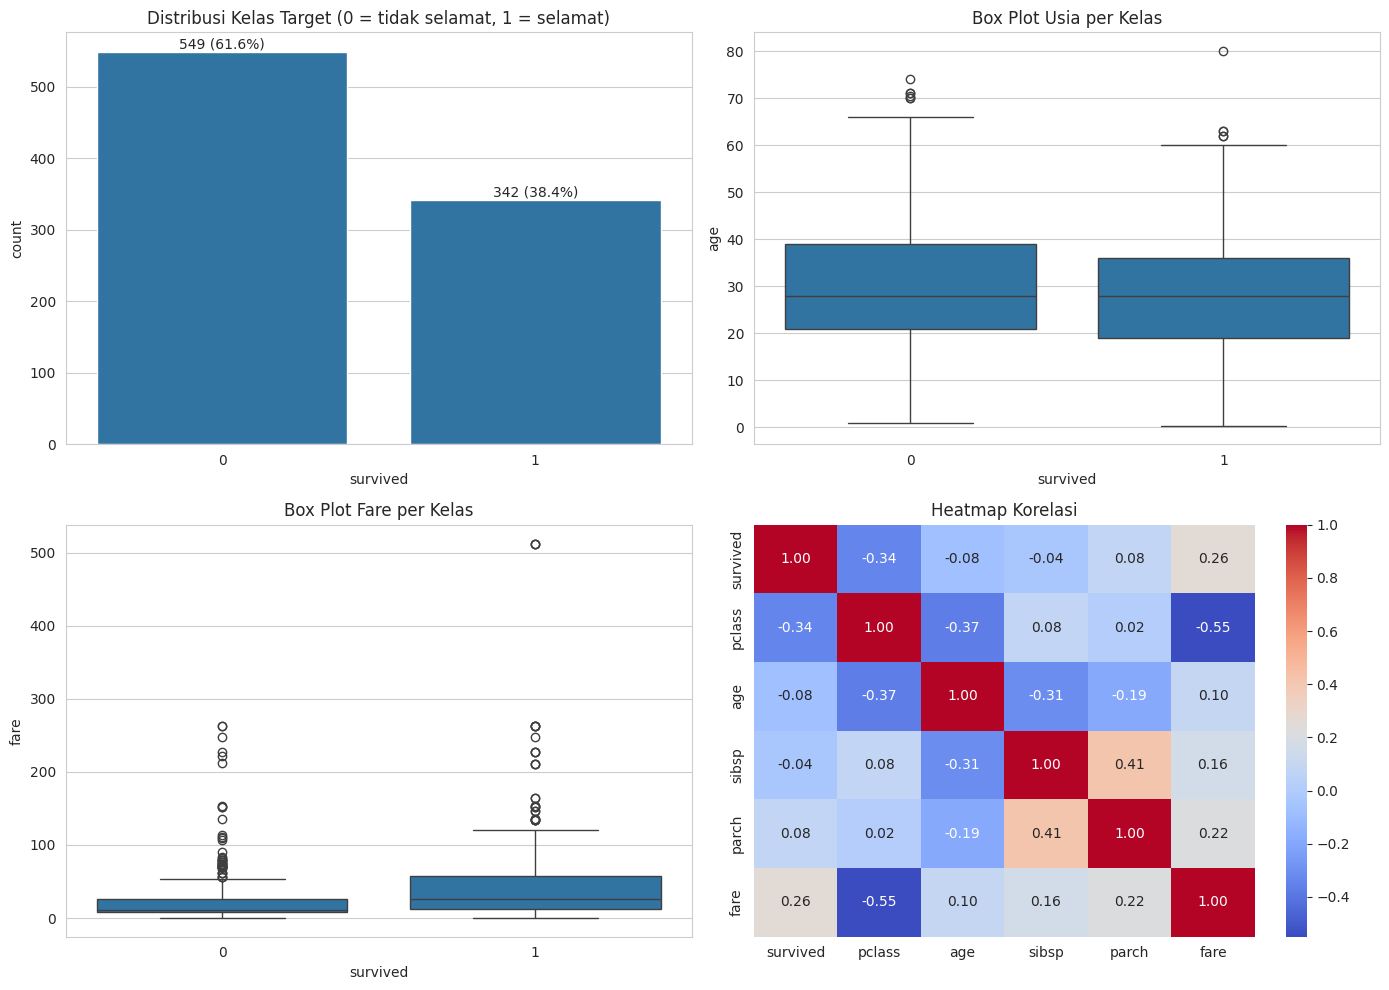

Tingkat selamat per jenis kelamin:
sex
female    0.742
male      0.189
Name: survived, dtype: float64
Tingkat selamat per kelas tiket:
pclass
1    0.630
2    0.473
3    0.242
Name: survived, dtype: float64


In [ ]:
fitur_num = ['age', 'sibsp', 'parch', 'fare']
display(df_b[['survived'] + fitur_num].describe().round(2))

fig, ax = plt.subplots(2, 2, figsize=(14, 10))
sns.countplot(x='survived', data=df_b, ax=ax[0, 0])
ax[0, 0].set_title('Distribusi Kelas Target (0 = tidak selamat, 1 = selamat)')
for k, v in df_b['survived'].value_counts().items():
    ax[0, 0].text(k, v + 5, f'{v} ({v/len(df_b):.1%})', ha='center')

sns.boxplot(x='survived', y='age', data=df_b, ax=ax[0, 1]); ax[0, 1].set_title('Box Plot Usia per Kelas')
sns.boxplot(x='survived', y='fare', data=df_b, ax=ax[1, 0]); ax[1, 0].set_title('Box Plot Fare per Kelas')

sns.heatmap(df_b[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare']].corr(),
            annot=True, fmt='.2f', cmap='coolwarm', ax=ax[1, 1])
ax[1, 1].set_title('Heatmap Korelasi')
plt.tight_layout(); plt.show()

print('Tingkat selamat per jenis kelamin:'); print(df_b.groupby('sex')['survived'].mean().round(3))
print('Tingkat selamat per kelas tiket:'); print(df_b.groupby('pclass')['survived'].mean().round(3))

**Temuan B2:**
- **Bar chart:** 549 tidak selamat (61,6%) vs 342 selamat (38,4%); kelas tidak seimbang ringan (rasio 1,61:1)
- **Box plot usia:** sebaran usia kedua kelas tumpang tindih; penumpang selamat sedikit lebih muda, perbedaannya kecil
- **Box plot fare:** penumpang selamat cenderung membayar tiket lebih mahal; fare sangat condong ke kanan dengan banyak outlier
- **Heatmap:** pclass berkorelasi negatif dengan survived, fare positif; pclass dan fare saling berkorelasi cukup kuat (kelas 1 = tiket mahal).
- **Ringkasan angka:** tingkat selamat perempuan 74,2% vs laki-laki 18,9%; kelas 1: 63,0%, kelas 2: 47,3%, kelas 3: 24,2%.

## B3. Preprocessing
- **Duplikat:** baris dengan nilai fitur identik dipertahankan: dataset tidak punya ID penumpang, jadi kemiripan atribut (mis. satu keluarga) belum tentu data ganda
- **Missing values:** age diimputasi median, embarked dengan modus. Imputasi ada di dalam pipeline sehingga nilainya dipelajari hanya dari data latih (tanpa leakage)
- **Outlier:** fare sangat condong ke kanan (tiket kelas 1 mahal, valid) Outlier tidak dihapus, tetapi fare ditransformasi log1p untuk meredam pengaruhnya
- **Encoding & scaling:** One-Hot untuk pclass, sex, embarked ; StandardScaler untuk fitur numerik
- **Ketidakseimbangan kelas:** rasio kelas dicek di bawah; ditangani dengan class_weight='balanced'

In [ ]:
cols = ['survived', 'pclass', 'sex', 'age', 'sibsp', 'parch', 'fare', 'embarked']
df = df_b[cols].copy()
print('Baris duplikat (fitur identik):', int(df.duplicated().sum()), '-> dipertahankan')

q1, q3 = df['fare'].quantile([.25, .75]); iqr = q3 - q1
n_out = int((df['fare'] > q3 + 1.5 * iqr).sum())
print(f'Outlier fare (IQR): {n_out} baris ({n_out/len(df):.1%}) -> dipertahankan, ditransformasi log1p')
df['fare_log'] = np.log1p(df['fare'])

kelas = df['survived'].value_counts()
print(f'\nKelas 0: {kelas[0]} ({kelas[0]/len(df):.1%}) | Kelas 1: {kelas[1]} ({kelas[1]/len(df):.1%}) '
      f'| rasio mayoritas:minoritas = {kelas.max()/kelas.min():.2f}:1')

num_cols = ['age', 'sibsp', 'parch', 'fare_log']
cat_cols = ['pclass', 'sex', 'embarked']
prep = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imp', SimpleImputer(strategy='most_frequent')),
                      ('oh', OneHotEncoder(drop='first', dtype=float))]), cat_cols)])
X = df[num_cols + cat_cols]
y = df['survived']

Baris duplikat (fitur identik): 111 -> dipertahankan
Outlier fare (IQR): 116 baris (13.0%) -> dipertahankan, ditransformasi log1p

Kelas 0: 549 (61.6%) | Kelas 1: 342 (38.4%) | rasio mayoritas:minoritas = 1.61:1


## B4. Pemilihan Fitur
Metode: uji ANOVA F (SelectKBest dengan f_classif) pada fitur hasil preprocessing

 **Aturan:** fitur dipertahankan jika p-value < 0,05. Fitur yang lolos dipakai persis sama pada pipeline model

In [ ]:
Xp = prep.fit_transform(X, y)
nama = prep.get_feature_names_out()
skor, pval = f_classif(Xp, y)
sel = pd.DataFrame({'fitur': nama, 'skor_F': skor, 'p_value': pval}).sort_values('skor_F', ascending=False)
sel['dipertahankan'] = sel['p_value'] < 0.05
display(sel.round(4).reset_index(drop=True))
idx_pilih = [list(nama).index(f) for f in sel.loc[sel['dipertahankan'], 'fitur']]
def pilih_kolom(Z):
    return Z[:, idx_pilih]
print(f'Jumlah fitur dipertahankan: {len(idx_pilih)} dari {len(sel)}')
print('Dibuang:', sel.loc[~sel['dipertahankan'], 'fitur'].tolist())

,fitur,skor_F,p_value,dipertahankan
0,cat__sex_male,372.4057,0.0000,True
1,num__fare_log,108.5415,0.0000,True
2,cat__pclass_3,103.0576,0.0000,True
3,cat__embarked_S,20.3745,0.0000,True
4,cat__pclass_2,7.8148,0.0053,True
5,num__parch,5.9635,0.0148,True
6,num__age,3.7615,0.0528,False
7,num__sibsp,1.1106,0.2922,False
8,cat__embarked_Q,0.0118,0.9134,False


Jumlah fitur dipertahankan: 6 dari 9
Dibuang: ['num__age', 'num__sibsp', 'cat__embarked_Q']


**Temuan B4:** 6 dari 9 fitur hasil encoding dipertahankan (sex_male, fare_log, pclass_3, embarked_S, pclass_2, parch). Dibuang: age (p = 0,053, sedikit di atas batas), sibsp (p = 0,29), embarked_Q (p = 0,91) karena tidak berhubungan signifikan dengan target

## B5. Pembagian Data
Split 80:20 dengan stratify=y dan random_state=42 agar proporsi kelas terjaga.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RS, stratify=y)
print('Data latih:', X_train.shape, '| Data uji:', X_test.shape)
print('Proporsi kelas 1 -> keseluruhan: %.3f | latih: %.3f | uji: %.3f' % (y.mean(), y_train.mean(), y_test.mean()))

Data latih: (712, 7) | Data uji: (179, 7)
Proporsi kelas 1 -> keseluruhan: 0.384 | latih: 0.383 | uji: 0.385


## B6. Pemodelan

Intercept: 2.4664


,fitur,koefisien,odds_ratio
0,cat__sex_male,-2.4300,0.0880
1,cat__pclass_3,-1.1224,0.3255
2,cat__embarked_S,-0.5042,0.6040
3,num__fare_log,0.3883,1.4744
4,cat__pclass_2,-0.3137,0.7308
5,num__parch,-0.1706,0.8431


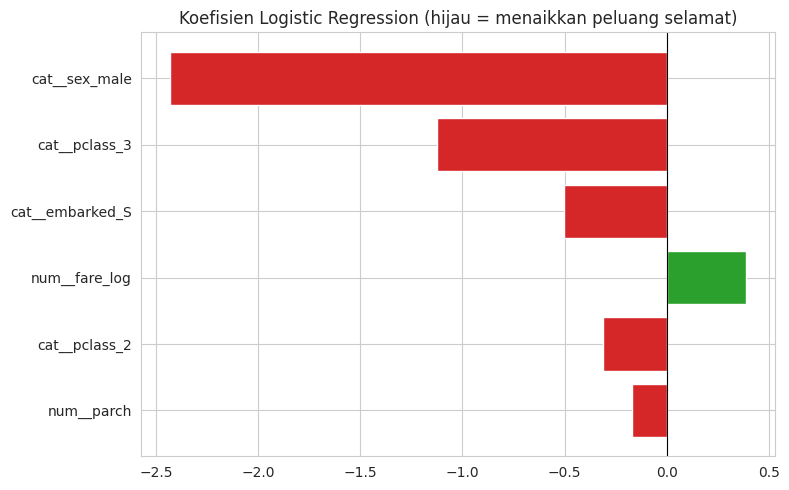

In [ ]:
model = Pipeline([
    ('prep', prep),
    ('select', FunctionTransformer(pilih_kolom)),
    ('clf', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=RS))])
model.fit(X_train, y_train)

dipakai = nama[idx_pilih]
clf = model.named_steps['clf']
print('Intercept:', round(clf.intercept_[0], 4))
koef = pd.DataFrame({'fitur': dipakai, 'koefisien': clf.coef_[0]})
koef['odds_ratio'] = np.exp(koef['koefisien'])
koef = koef.sort_values('koefisien', key=abs, ascending=False).reset_index(drop=True)
display(koef.round(4))

plt.figure(figsize=(8, 5))
k2 = koef.iloc[::-1]
plt.barh(k2['fitur'], k2['koefisien'], color=np.where(k2['koefisien'] > 0, 'tab:green', 'tab:red'))
plt.axvline(0, color='k', lw=.8); plt.title('Koefisien Logistic Regression (hijau = menaikkan peluang selamat)')
plt.tight_layout(); plt.show()

**Interpretasi koefisien** (positif = menaikkan peluang selamat; odds ratio > 1 menaikkan, < 1 menurunkan):
- sex_male (-2,43; OR 0,09): laki-laki punya odds selamat sekitar 91% lebih rendah dibanding perempuan; pengaruh terbesar
- pclass_3 (-1,12; OR 0,33) dan `pclass_2` (-0,31; OR 0,73): dibanding kelas 1, odds selamat lebih rendah, terutama kelas 3
- embarked_S (-0,50; OR 0,60): naik dari Southampton menurunkan odds dibanding Cherbourg
- fare_log (+0,39; OR 1,47): tiap kenaikan 1 simpangan baku log-fare menaikkan odds selamat sekitar 47%, dengan fitur lain tetap
- parch (-0,17; OR 0,84): tiap +1 simpangan baku jumlah orang tua/anak menurunkan odds sekitar 16%

## B7. Evaluasi

,Data uji
Accuracy,0.7430
Precision,0.6494
Recall,0.7246
F1-score,0.6849
ROC-AUC,0.8148


Accuracy data latih: 0.7711
Confusion matrix [[TN, FP], [FN, TP]]: [[83, 27], [19, 50]]


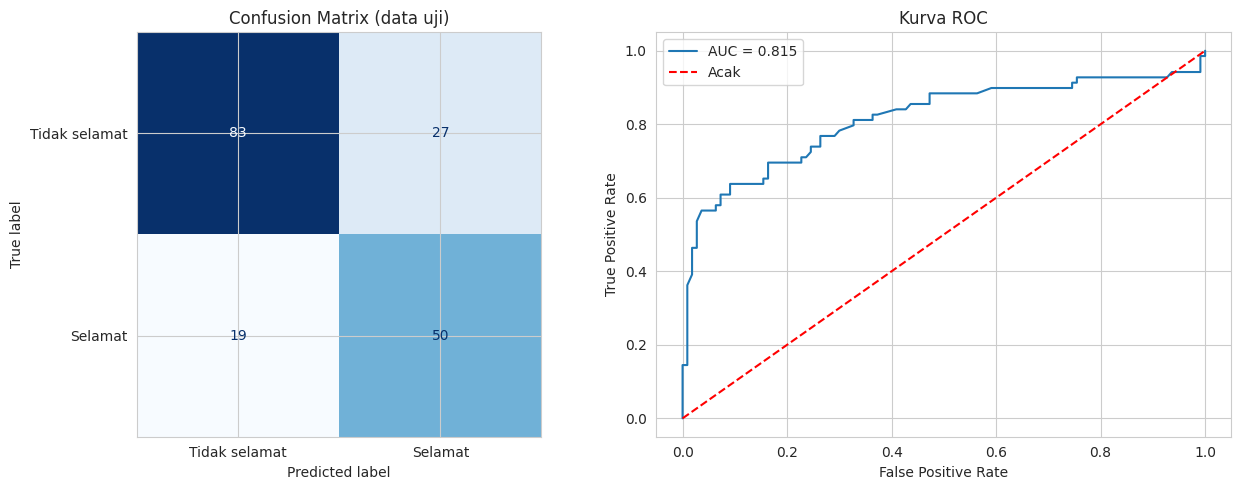

In [ ]:
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

metrik = pd.Series({'Accuracy': accuracy_score(y_test, y_pred), 'Precision': precision_score(y_test, y_pred),
                    'Recall': recall_score(y_test, y_pred), 'F1-score': f1_score(y_test, y_pred),
                    'ROC-AUC': roc_auc_score(y_test, y_prob)}).round(4)
display(metrik.to_frame('Data uji'))
print('Accuracy data latih:', round(accuracy_score(y_train, model.predict(X_train)), 4))

cm = confusion_matrix(y_test, y_pred)
print('Confusion matrix [[TN, FP], [FN, TP]]:', cm.tolist())

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(cm, display_labels=['Tidak selamat', 'Selamat']).plot(ax=ax[0], cmap='Blues', colorbar=False)
ax[0].set_title('Confusion Matrix (data uji)')
fpr, tpr, _ = roc_curve(y_test, y_prob)
ax[1].plot(fpr, tpr, label=f'AUC = {metrik["ROC-AUC"]:.3f}'); ax[1].plot([0, 1], [0, 1], 'r--', label='Acak')
ax[1].set(xlabel='False Positive Rate', ylabel='True Positive Rate', title='Kurva ROC'); ax[1].legend()
plt.tight_layout(); plt.show()

## B8. Analisis Performa

- **Metrik paling relevan:** accuracy 74,3% hanya sedikit di atas tebakan kelas mayoritas (61,6%), jadi tidak cukup. Untuk tujuan mengenali penumpang yang selamat, **recall (72,5%)** penting agar yang selamat tidak terlewat, dilengkapi **F1 (0,685)** dan **AUC (0,815)** yang tidak terpengaruh ketidakseimbangan kelas dan ambang klasifikasi
- **Jenis kesalahan:** confusion matrix [[83, 27], [19, 50]]. False positive (27: diprediksi selamat padahal tidak) lebih banyak daripada false negative (19: diprediksi tidak selamat padahal selamat). Hal ini wajar karena class_weight='balanced' mendorong model lebih sering memprediksi kelas selamat, sehingga precision (64,9%) lebih rendah dari recall
- **Overfitting:** accuracy latih 77,1% vs uji 74,3% (selisih kecil), tidak ada overfitting berarti
- **Keterbatasan:** (1) model linear pada log-odds, interaksi seperti jenis kelamin x kelas tidak tertangkap; (2) age memiliki sekitar 20% data kosong yang diimputasi median; (3) data uji hanya 179 baris sehingga metrik bisa bergeser bila split berubah; (4) seleksi fitur memakai seluruh data (eksploratif); (5) hanya mencakup atribut penumpang, tanpa faktor situasional (lokasi kabin, akses sekoci)